In [1]:
import sys, json
from pathlib import Path
p = Path.cwd()
while not (p / "data.py").exists():
    p = p.parent
sys.path.insert(0, str(p))
import numpy as np, matplotlib.pyplot as plt

res = json.load(open(p / "results" / "metrics.json"))
tim = json.load(open(p / "results" / "timing.json"))
names = list(res)

print("| Mô hình | Train acc | Val acc | Test acc | Test F1 macro | Train − test (điểm) |")
print("|---|---|---|---|---|---|")
for n in names:
    a = {s: res[n][s]["accuracy"] * 100 for s in ["train", "val", "test"]}
    print(f"| {n} | {a['train']:.2f} | {a['val']:.2f} | {a['test']:.2f} | "
          f"{res[n]['test']['f1_macro']*100:.2f} | {a['train'] - a['test']:.2f} |")

print("\n| Mô hình | Tập | Accuracy | Precision | Recall | F1 |")
print("|---|---|---|---|---|---|")
for n in names:
    for s in ["train", "val", "test"]:
        r = res[n][s]
        print(f"| {n} | {s} | {r['accuracy']*100:.2f} | {r['precision_macro']*100:.2f} | "
              f"{r['recall_macro']*100:.2f} | {r['f1_macro']*100:.2f} |")

| Mô hình | Train acc | Val acc | Test acc | Test F1 macro | Train − test (điểm) |
|---|---|---|---|---|---|
| GaussianNB | 80.29 | 79.78 | 81.59 | 81.44 | -1.30 |
| MultinomialNB | 82.55 | 82.38 | 83.74 | 83.60 | -1.19 |
| BernoulliNB | 83.82 | 83.53 | 84.50 | 84.32 | -0.68 |
| Softmax | 92.87 | 92.02 | 92.31 | 92.20 | 0.56 |
| MLP | 99.95 | 97.85 | 98.13 | 98.12 | 1.82 |
| RandomForest | 99.91 | 96.15 | 96.21 | 96.17 | 3.70 |

| Mô hình | Tập | Accuracy | Precision | Recall | F1 |
|---|---|---|---|---|---|
| GaussianNB | train | 80.29 | 81.92 | 79.91 | 80.14 |
| GaussianNB | val | 79.78 | 81.55 | 79.30 | 79.58 |
| GaussianNB | test | 81.59 | 83.20 | 81.23 | 81.44 |
| MultinomialNB | train | 82.55 | 83.24 | 82.27 | 82.43 |
| MultinomialNB | val | 82.38 | 83.00 | 82.02 | 82.21 |
| MultinomialNB | test | 83.74 | 84.45 | 83.44 | 83.60 |
| BernoulliNB | train | 83.82 | 83.94 | 83.57 | 83.66 |
| BernoulliNB | val | 83.53 | 83.57 | 83.21 | 83.29 |
| BernoulliNB | test | 84.50 | 84.57 | 84.2

In [2]:
n_test = 10000
print("Sai số chuẩn của accuracy test (±1,96·SE là khoảng tin cậy xấp xỉ 95%):")
for n in names:
    a = res[n]["test"]["accuracy"]
    se = np.sqrt(a * (1 - a) / n_test)
    print(f"  {n:14s}: {a*100:.2f}% ± {1.96*se*100:.2f}")

print("\n| Mô hình | Huấn luyện: trung vị (min–max) s | Dự đoán 10.000 ảnh: trung vị (min–max) s |")
print("|---|---|---|")
for n in names:
    f, q = np.array(tim["fit"][n]), np.array(tim["predict"][n])
    print(f"| {n} | {np.median(f):.2f} ({f.min():.2f}–{f.max():.2f}) | "
          f"{np.median(q):.3f} ({q.min():.3f}–{q.max():.3f}) |")
print("\nMôi trường:", tim["env"])

Sai số chuẩn của accuracy test (±1,96·SE là khoảng tin cậy xấp xỉ 95%):
  GaussianNB    : 81.59% ± 0.76
  MultinomialNB : 83.74% ± 0.72
  BernoulliNB   : 84.50% ± 0.71
  Softmax       : 92.31% ± 0.52
  MLP           : 98.13% ± 0.27
  RandomForest  : 96.21% ± 0.37

| Mô hình | Huấn luyện: trung vị (min–max) s | Dự đoán 10.000 ảnh: trung vị (min–max) s |
|---|---|---|
| GaussianNB | 0.45 (0.42–0.55) | 0.646 (0.578–0.765) |
| MultinomialNB | 5.15 (1.66–6.92) | 0.021 (0.020–0.023) |
| BernoulliNB | 5.58 (2.05–5.87) | 0.024 (0.023–0.024) |
| Softmax | 3.37 (3.34–3.77) | 0.003 (0.003–0.006) |
| MLP | 264.14 (196.62–328.46) | 0.032 (0.032–0.036) |
| RandomForest | 83.76 (77.76–97.92) | 0.328 (0.309–0.470) |

Môi trường: {'platform': 'Windows-11-10.0.26200-SP0', 'processor': 'Intel64 Family 6 Model 170 Stepping 4, GenuineIntel', 'cpu_count': 22, 'python': '3.13.0', 'numpy': '2.5.3'}


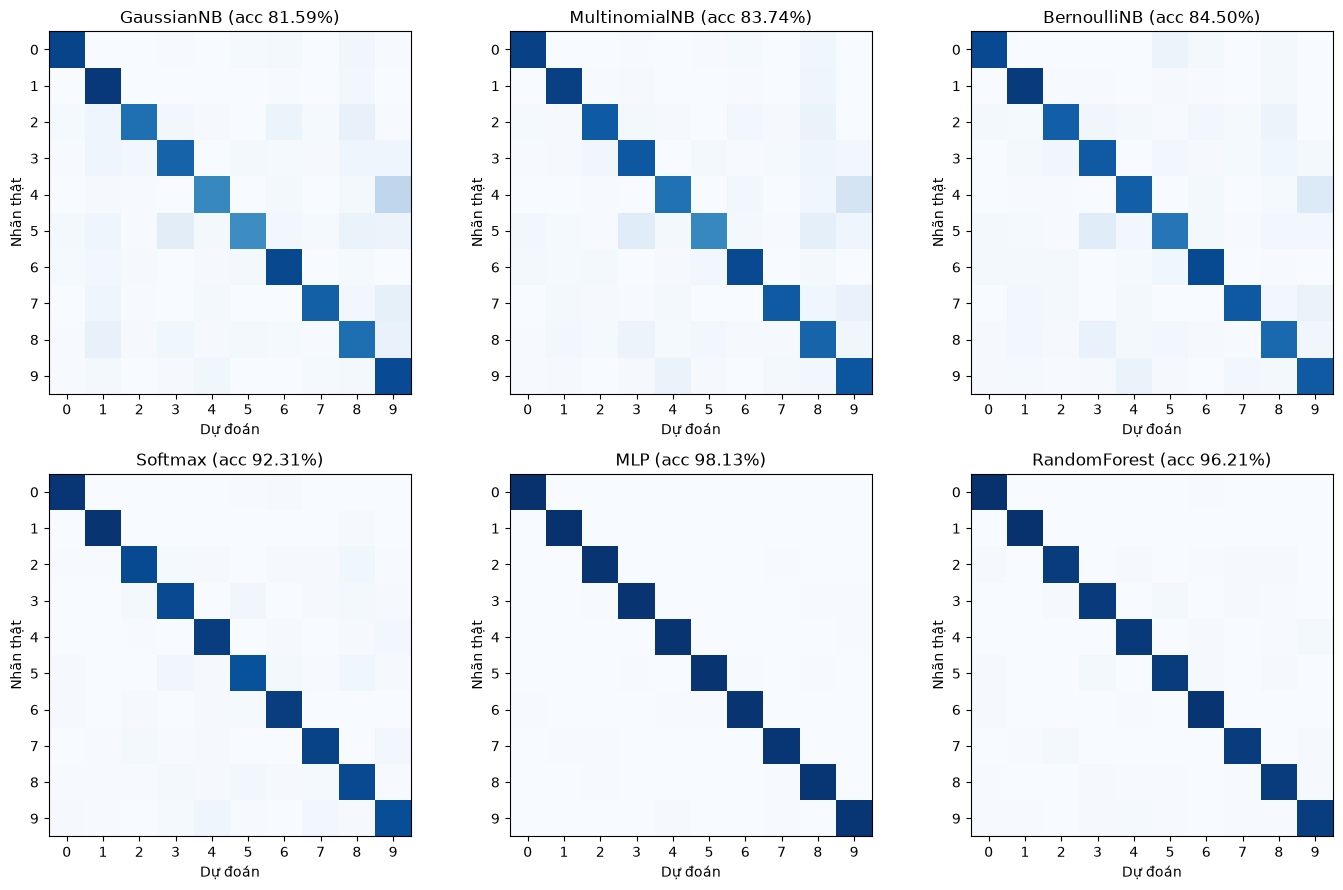

GaussianNB | nhầm nhiều nhất (thật → dự đoán: số ảnh): 4→9: 272, 5→3: 93, 7→9: 86
MultinomialNB | nhầm nhiều nhất (thật → dự đoán: số ảnh): 4→9: 173, 5→3: 104, 5→8: 79
BernoulliNB | nhầm nhiều nhất (thật → dự đoán: số ảnh): 4→9: 133, 5→3: 104, 8→3: 67
Softmax | nhầm nhiều nhất (thật → dự đoán: số ảnh): 9→4: 40, 2→8: 37, 5→8: 32
MLP | nhầm nhiều nhất (thật → dự đoán: số ảnh): 9→4: 8, 7→2: 8, 4→9: 7
RandomForest | nhầm nhiều nhất (thật → dự đoán: số ảnh): 7→2: 22, 4→9: 21, 3→5: 16


In [3]:
fig, ax = plt.subplots(2, 3, figsize=(14, 9))
for a, n in zip(ax.ravel(), names):
    C = np.array(res[n]["test"]["confusion_matrix"], dtype=float)
    a.imshow(C / C.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
    a.set_title(f"{n} (acc {res[n]['test']['accuracy']*100:.2f}%)")
    a.set_xlabel("Dự đoán"); a.set_ylabel("Nhãn thật")
    a.set_xticks(range(10)); a.set_yticks(range(10))
plt.tight_layout()
plt.savefig(p / "report" / "confusion_test_all.png", dpi=150)
plt.show()

for n in names:
    C = np.array(res[n]["test"]["confusion_matrix"])
    off = C.copy(); np.fill_diagonal(off, 0)
    top = np.dstack(np.unravel_index(np.argsort(-off, axis=None)[:3], off.shape))[0]
    print(n, "| nhầm nhiều nhất (thật → dự đoán: số ảnh):",
          ", ".join(f"{i}→{j}: {off[i, j]}" for i, j in top))

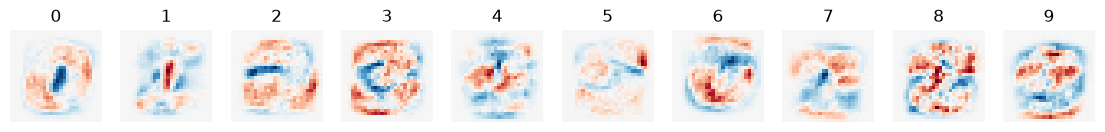

In [4]:
from data import get_splits
import softmax as sm
d = get_splits()
W, b, _ = sm.train(d["X_train"], d["y_train"], d["X_val"], d["y_val"],
                   lr=0.1, epochs=30, batch_size=128, seed=0, track=False)
fig, ax = plt.subplots(1, 10, figsize=(14, 2))
for c in range(10):
    vmax = np.abs(W[:, c]).max()
    ax[c].imshow(W[:, c].reshape(28, 28), cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    ax[c].set_title(c); ax[c].axis("off")
plt.savefig(p / "report" / "softmax_weights.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
from scipy.stats import binomtest
y_test = get_splits()["y_test"]
pa = np.load(p / "results" / "preds_MLP.npz")["test"]
pb = np.load(p / "results" / "preds_RandomForest.npz")["test"]
b = int(((pa == y_test) & (pb != y_test)).sum())   # MLP đúng, RF sai
c = int(((pa != y_test) & (pb == y_test)).sum())   # MLP sai, RF đúng
print("MLP đúng & RF sai:", b, "| MLP sai & RF đúng:", c, "| p =", binomtest(b, b + c, 0.5).pvalue)

MLP đúng & RF sai: 246 | MLP sai & RF đúng: 54 | p = 1.9615870763466144e-30


In [6]:
from data import get_splits
y = get_splits()["y_test"]
print("| Mô hình | Acc 5.000 ảnh đầu (%) | Acc 5.000 ảnh sau (%) |")
print("|---|---|---|")
for n in names:
    ok = np.load(p / "results" / f"preds_{n}.npz")["test"] == y
    print(f"| {n} | {ok[:5000].mean()*100:.2f} | {ok[5000:].mean()*100:.2f} |")

| Mô hình | Acc 5.000 ảnh đầu (%) | Acc 5.000 ảnh sau (%) |
|---|---|---|
| GaussianNB | 76.08 | 87.10 |
| MultinomialNB | 79.54 | 87.94 |
| BernoulliNB | 80.00 | 89.00 |
| Softmax | 90.24 | 94.38 |
| MLP | 97.28 | 98.98 |
| RandomForest | 94.64 | 97.78 |
